# Week 9 - Gradient Boosting

## Gradient Boosting

In [1]:
from prep import *
from sklearn.ensemble import GradientBoostingRegressor

X_train, X_test, y_train, y_test, meta = load_model_data()

gb_pipe = make_pipeline(*preprocess(scale=False), GradientBoostingRegressor(random_state=0))
gb_grid = {"gradientboostingregressor__n_estimators": [100, 300],
           "gradientboostingregressor__learning_rate": [0.01, 0.05, 0.1],
           "gradientboostingregressor__max_depth": [2, 3],
           "gradientboostingregressor__subsample": [0.8, 1.0]}
gb_search = tune(gb_pipe, gb_grid, X_train, y_train)   # TimeSeriesSplit(5), RMSE
gb_best = gb_search.best_estimator_

train 1992-03-31 to 2014-12-31  (92, 27)
test  2015-03-31 to 2025-12-31  (44, 27)
best params: {'gradientboostingregressor__learning_rate': 0.1, 'gradientboostingregressor__max_depth': 2, 'gradientboostingregressor__n_estimators': 100, 'gradientboostingregressor__subsample': 0.8}
best CV root_mean_squared_error: 0.4313


,RMSE,MAE,R2,DirAcc,n
model - train (in-sample),0.039,0.033,0.996,0.913,92.0
model - test,0.177,0.116,0.514,0.636,44.0
naive - test,0.104,0.066,0.832,NaN,44.0
model - test excl. 2020-21,0.100,0.076,0.775,0.667,36.0
naive - test excl. 2020-21,0.089,0.060,0.824,NaN,36.0


recorded 'Gradient boosting' -> /workspaces/DX799-O1/model_data/results


,RMSE,MAE,R2,DirAcc,n
model - train (in-sample),0.039,0.033,0.996,0.913,92.0
model - test,0.177,0.116,0.514,0.636,44.0
naive - test,0.104,0.066,0.832,NaN,44.0
model - test excl. 2020-21,0.100,0.076,0.775,0.667,36.0
naive - test excl. 2020-21,0.089,0.060,0.824,NaN,36.0


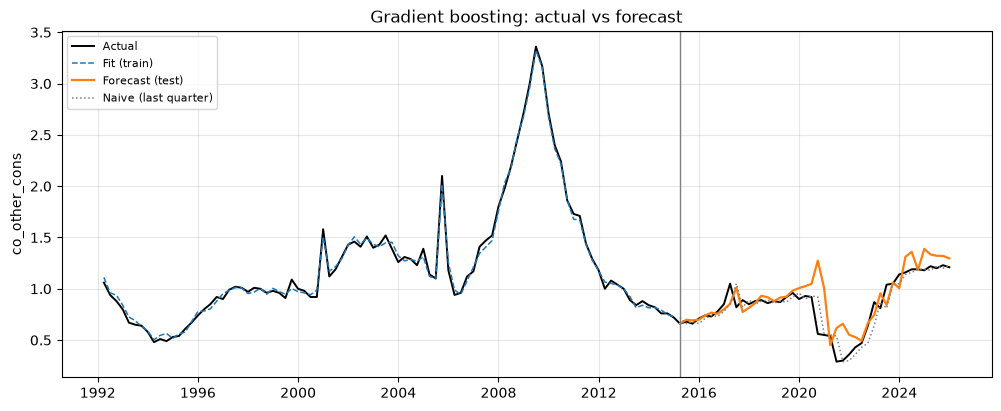

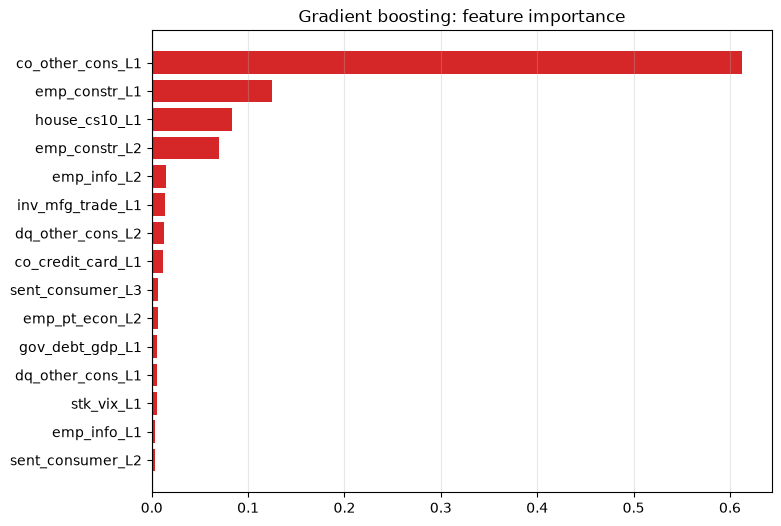

In [3]:
display(score(gb_best, X_train, X_test, y_train, y_test))
plot_forecast(gb_best, X_train, X_test, y_train, y_test, title="Gradient boosting: actual vs forecast")
plot_feature_weights(gb_best, X_train, top=15, title="Gradient boosting: feature importance")
record("Gradient boosting", gb_best, X_train, X_test, y_train, y_test, search=gb_search, notes=str(gb_search.best_params_))